# Setup

This notebook is the modern version of the Py4Geo tutorials (2020): raster and vector data, spectral indices,
unsupervised classification and regridding, now on a real Sentinel-2 image read straight from the cloud. The image
comes from Microsoft's Planetary Computer, which needs no account. The area is Belfast and Belfast Lough.

Libraries: **pystac-client** searches catalogues of satellite images; **planetary-computer** signs the links so the
files can be read; **rasterio** reads the images; **numpy** does arithmetic on them; **geopandas** handles vector data
(points and polygons); **scikit-learn** does the clustering; **scipy** the interpolation; **matplotlib** the figures.
The first cell installs what Google Colab lacks.

In [1]:
import importlib.util, os, subprocess, sys
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")          # avoids a harmless CPU-count warning from scikit-learn on Windows
need = [p for p in ["pystac_client", "planetary_computer", "rasterio", "geopandas"] if importlib.util.find_spec(p) is None]
if need:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *[p.replace("_", "-") for p in need]], check=True)
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
from shapely.geometry import Point
import pystac_client, planetary_computer
from sklearn.cluster import KMeans
from scipy.interpolate import griddata
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110})
rng = np.random.default_rng(1)

# Find an image: catalogues and STAC

Satellite archives are described by **STAC** (SpatioTemporal Asset Catalog) catalogues. Each **item** is one image
(one place, one time) and lists its **assets**, the files for each band. We search the Sentinel-2 Level-2A collection
(surface reflectance, corrected for the atmosphere) for summer 2025 over Belfast, keep images with under 10% cloud,
and take the clearest.

In [2]:
BBOX = [-6.05, 54.55, -5.85, 54.65]                 # west, south, east, north in degrees (WGS84)
catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
search = catalog.search(collections=["sentinel-2-l2a"], bbox=BBOX, datetime="2025-05-01/2025-08-31", query={"eo:cloud_cover": {"lt": 10}})
items = sorted(search.items(), key=lambda i: i.properties["eo:cloud_cover"])
item = items[0]
print(f"{len(items)} images found; using {item.id}")
print("date:", item.properties["datetime"][:10], "| cloud cover:", round(item.properties["eo:cloud_cover"], 3), "%",
      "| tile:", item.properties["s2:mgrs_tile"], "| processing baseline:", item.properties["s2:processing_baseline"])
print("bands available:", ", ".join(k for k in item.assets if k.startswith("B")))

10 images found; using S2B_MSIL2A_20250713T114349_R123_T30UUF_20250713T134456
date: 2025-07-13 | cloud cover: 0.003 % | tile: 30UUF | processing baseline: 05.11
bands available: B01, B02, B03, B04, B05, B06, B07, B08, B09, B11, B12, B8A


# Read the bands for our area: what a raster is

A **raster** is a grid of numbers (one grid per **band**) plus the information that places it on the Earth: the
**coordinate reference system** (CRS) and the **transform** (the coordinates of the top-left corner and the pixel
size). Sentinel-2 files are **Cloud-Optimised GeoTIFFs**, so we can read just the window covering our area instead of
the whole 110 km tile. Bands come at 10 m (blue B02, green B03, red B04, near-infrared B08) and 20 m (shortwave
infrared B11); we read B11 onto the 10 m grid.

The files store whole numbers (digital numbers, DN). **Reflectance**, the share of sunlight the surface reflects
(0 to 1), is DN / 10000 for older images. Since processing baseline 04.00 (January 2022), an offset of 1000 was added,
so reflectance = (DN − 1000) / 10000. Forgetting this skews every index computed from the bands.

In [3]:
BANDS = {"B02": "blue", "B03": "green", "B04": "red", "B08": "nir", "B11": "swir"}
with rasterio.open(item.assets["B04"].href) as ref:
    crs = ref.crs
    bounds = transform_bounds("EPSG:4326", crs, *BBOX)
    win = from_bounds(*bounds, transform=ref.transform).round_offsets().round_lengths()
    transform = ref.window_transform(win)
    shape = (int(win.height), int(win.width))
offset = 1000 if float(item.properties["s2:processing_baseline"]) >= 4.0 else 0
img = {}
for b, name in BANDS.items():
    with rasterio.open(item.assets[b].href) as src:
        w = from_bounds(*bounds, transform=src.transform)
        dn = src.read(1, window=w, out_shape=shape, resampling=rasterio.enums.Resampling.bilinear).astype("float32")
    img[name] = np.where(dn == 0, np.nan, (dn - offset) / 10000)          # 0 means no data
print("CRS:", crs, "| pixel size:", transform.a, "m | rows x columns:", shape, f"| area {shape[0] * shape[1] / 1e4:.0f} km²")
for name, a in img.items():
    print(f"{name:6s} reflectance: median {np.nanmedian(a):.3f}, 2nd-98th percentile {np.nanpercentile(a, 2):.3f} to {np.nanpercentile(a, 98):.3f}")

CRS: EPSG:32630 | pixel size: 10.0 m | rows x columns: (1166, 1338) | area 156 km²
blue   reflectance: median 0.041, 2nd-98th percentile 0.015 to 0.157
green  reflectance: median 0.062, 2nd-98th percentile 0.029 to 0.174
red    reflectance: median 0.050, 2nd-98th percentile 0.014 to 0.190
nir    reflectance: median 0.256, 2nd-98th percentile 0.014 to 0.509
swir   reflectance: median 0.174, 2nd-98th percentile 0.009 to 0.290


# True and false colour

A **true-colour** image puts the red, green and blue bands into the red, green and blue channels of the screen: it
looks like a photograph. A **false-colour** image puts near-infrared into red: healthy vegetation reflects strongly in
the near-infrared, so it shows **bright red**, while water (which absorbs near-infrared) is **black** and built-up
areas are **grey-blue**.

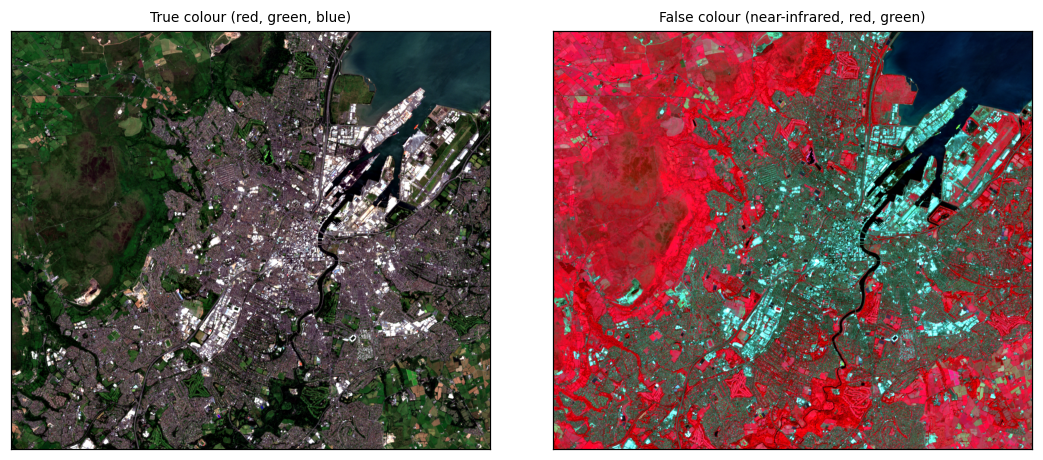

In [4]:
def stretch(a, lo=2, hi=98):
    p1, p2 = np.nanpercentile(a, [lo, hi]); return np.clip((a - p1) / (p2 - p1), 0, 1)
true = np.dstack([stretch(img["red"]), stretch(img["green"]), stretch(img["blue"])])
false = np.dstack([stretch(img["nir"]), stretch(img["red"]), stretch(img["green"])])
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, im, t in zip(ax, [true, false], ["True colour (red, green, blue)", "False colour (near-infrared, red, green)"]):
    a.imshow(im); a.set_title(t, fontsize=9); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**How to read the images.** Both cover about 13 km × 11 km around Belfast at 10 m per pixel. In true colour, Belfast
Lough is the dark area at the top right, the city grey in the middle, and fields and hills green and brown. In false
colour the same scene separates more clearly: vegetation (parks, Cave Hill, farmland) is red, more intense where plants
are growing vigorously; water is near black; streets and roofs are blue-grey.

# Spectral indices: NDVI, NDWI and NDBI

An **index** combines two bands to highlight one kind of surface. Normalised differences have the form
(a − b) / (a + b), which ranges from −1 to +1 and cancels much of the effect of illumination:

- **NDVI** = (NIR − Red) / (NIR + Red): vegetation reflects NIR and absorbs red, so dense green vegetation scores about
  0.6–0.9, bare soil and built-up 0.1–0.3, water below 0.
- **NDWI** = (Green − NIR) / (Green + NIR): open water scores above 0, land below.
- **NDBI** = (SWIR − NIR) / (SWIR + NIR): built-up and bare surfaces reflect more shortwave infrared than NIR, so score
  higher; vegetation scores below 0.

NDVI: median +0.62, 10th percentile +0.06, 90th +0.89
NDWI: median -0.59, 10th percentile -0.79, 90th -0.10
NDBI: median -0.18, 10th percentile -0.41, 90th +0.11
share of the area with NDWI > 0 (open water): 7%; with NDVI > 0.5 (dense vegetation): 58%


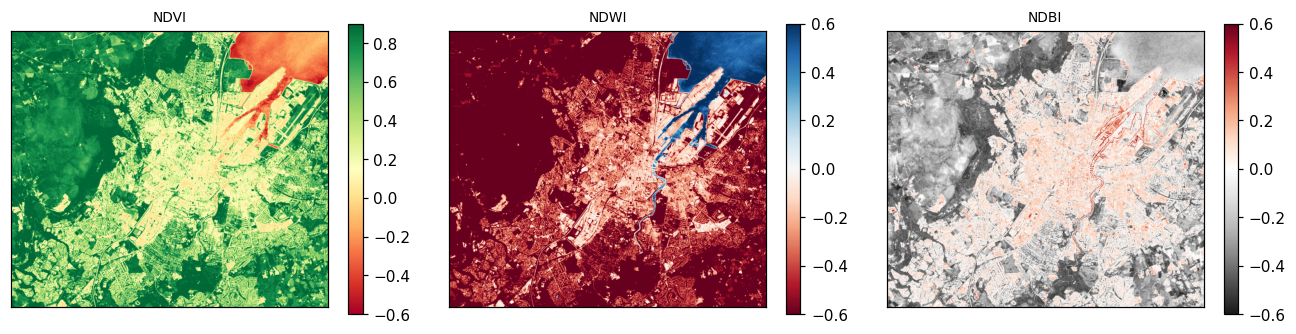

In [5]:
def nd(a, b):
    return (a - b) / (a + b)
ndvi, ndwi, ndbi = nd(img["nir"], img["red"]), nd(img["green"], img["nir"]), nd(img["swir"], img["nir"])
for name, a in [("NDVI", ndvi), ("NDWI", ndwi), ("NDBI", ndbi)]:
    print(f"{name}: median {np.nanmedian(a):+.2f}, 10th percentile {np.nanpercentile(a, 10):+.2f}, 90th {np.nanpercentile(a, 90):+.2f}")
print(f"share of the area with NDWI > 0 (open water): {np.nanmean(ndwi > 0):.0%}; with NDVI > 0.5 (dense vegetation): {np.nanmean(ndvi > 0.5):.0%}")
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, arr, t, cm in zip(ax, [ndvi, ndwi, ndbi], ["NDVI", "NDWI", "NDBI"], ["RdYlGn", "RdBu", "RdGy_r"]):
    m = a.imshow(arr, cmap=cm, vmin=-0.6, vmax=0.9 if t == "NDVI" else 0.6); a.set_title(t, fontsize=9); a.set_xticks([]); a.set_yticks([])
    fig.colorbar(m, ax=a, shrink=0.8)
plt.tight_layout(); plt.show()

**How to read the maps.** Each pixel's colour is its index value; the colour bar beside each map gives the scale.
In the NDVI map, green is dense vegetation and red is low or negative values (water, roofs, roads). In the NDWI map,
blue is water: Belfast Lough and the River Lagan stand out. In the NDBI map, dark is built-up. The printed shares turn
the maps into numbers.

# Vector data: places, buffers and statistics

**Vector** data describe features as points, lines or polygons with attributes. Here we create a few points of
interest with **geopandas**, project them to the image's CRS, draw a 300 m circle (a **buffer**) around each, and
average the indices inside each circle: a **zonal statistic**.

In [6]:
places = gpd.GeoDataFrame({"place": ["City Hall", "Belfast Lough", "Cave Hill", "Botanic Gardens", "Harbour estate"]},
                          geometry=[Point(-5.9301, 54.5965), Point(-5.885, 54.630), Point(-5.948, 54.640), Point(-5.932, 54.582), Point(-5.895, 54.615)],
                          crs="EPSG:4326").to_crs(crs)
places["geometry"] = places.buffer(300)
rows, cols = np.indices(shape)
xs, ys = rasterio.transform.xy(transform, rows.ravel(), cols.ravel())
pts = np.c_[xs, ys]
out = []
for _, p in places.iterrows():
    minx, miny, maxx, maxy = p.geometry.bounds
    inside = (pts[:, 0] >= minx) & (pts[:, 0] <= maxx) & (pts[:, 1] >= miny) & (pts[:, 1] <= maxy)
    inside &= np.hypot(pts[:, 0] - p.geometry.centroid.x, pts[:, 1] - p.geometry.centroid.y) <= 300
    out.append({"place": p.place, "pixels": int(inside.sum()), "NDVI": np.nanmean(ndvi.ravel()[inside]),
                "NDWI": np.nanmean(ndwi.ravel()[inside]), "NDBI": np.nanmean(ndbi.ravel()[inside])})
zs = pd.DataFrame(out).round(2)
print(zs.to_string(index=False))
print("\nmost vegetated:", zs.loc[zs.NDVI.idxmax(), "place"], "| wettest:", zs.loc[zs.NDWI.idxmax(), "place"], "| most built-up:", zs.loc[zs.NDBI.idxmax(), "place"])

          place  pixels  NDVI  NDWI  NDBI
      City Hall    2827  0.15 -0.18  0.08
  Belfast Lough    2828 -0.26  0.42 -0.03
      Cave Hill    2823  0.92 -0.84 -0.45
Botanic Gardens    2825  0.50 -0.48 -0.11
 Harbour estate    2833  0.08  0.01  0.05

most vegetated: Cave Hill | wettest: Belfast Lough | most built-up: City Hall


**How to read the table.** One row per place; "pixels" counts the 10 m pixels inside its 300 m circle (about 2,800);
the other columns are the mean index values there. Read down each column to rank the places. The line under the table
names the extremes, which should match what you know of each place: open water in the Lough, woodland on Cave Hill,
streets and roofs around City Hall and the harbour.

# Unsupervised classification: k-means

**K-means clustering** groups pixels by their spectra without being told what the groups are. It places k centres in
the five-band reflectance space, assigns each pixel to the nearest centre, moves each centre to the mean of its pixels,
and repeats until nothing changes. The analyst chooses k and afterwards names each cluster by looking at its average
spectrum. **Inertia** (the total squared distance of pixels to their centres) always falls as k grows; the "elbow",
where it stops falling quickly, suggests a sensible k.

inertia by k: {2: 233.5, 3: 169.1, 4: 122.7, 5: 89.8, 6: 76.9, 7: 65.1, 8: 56.6}


    blue  green    red    nir   swir   NDVI   NDWI   NDBI  share                   suggested name
0  0.040  0.051  0.028  0.021  0.020 -0.143  0.407 -0.029  0.076                            water
1  0.034  0.058  0.047  0.312  0.195  0.740 -0.687 -0.229  0.292                grass and pasture
2  0.205  0.224  0.237  0.266  0.265  0.059 -0.087 -0.001  0.029   bright roofs and bare surfaces
3  0.027  0.058  0.031  0.434  0.200  0.865 -0.764 -0.369  0.228  dense vegetation (trees, crops)
4  0.062  0.074  0.079  0.157  0.161  0.332 -0.358  0.011  0.375    built-up with some vegetation


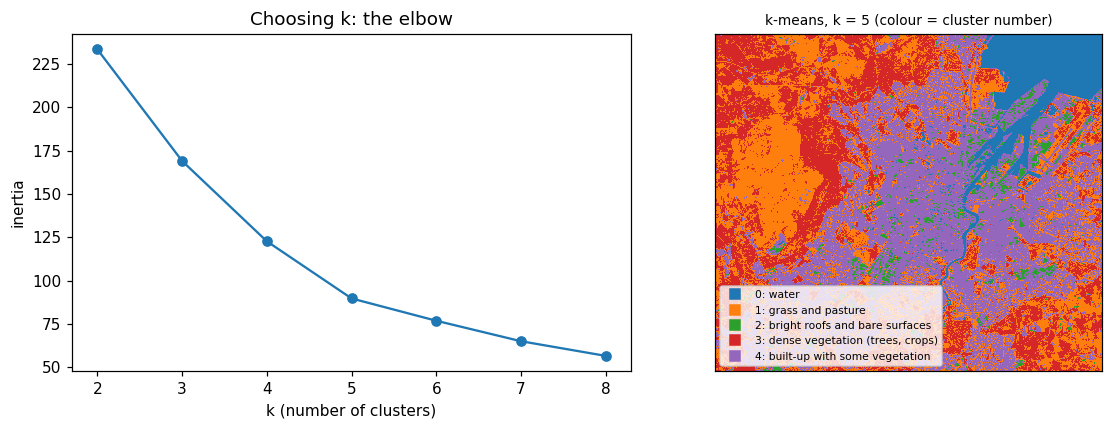

In [7]:
X = np.c_[[img[n].ravel() for n in BANDS.values()]].T
ok = np.isfinite(X).all(axis=1)
sample = X[ok][rng.choice(ok.sum(), 20000, replace=False)]
inertia = {k: KMeans(k, n_init=4, random_state=0).fit(sample).inertia_ for k in range(2, 9)}
print("inertia by k:", {k: round(v, 1) for k, v in inertia.items()})
km = KMeans(5, n_init=8, random_state=0).fit(sample)
labels = np.full(X.shape[0], -1); labels[ok] = km.predict(X[ok]); labels = labels.reshape(shape)
centres = pd.DataFrame(km.cluster_centers_, columns=list(BANDS.values()))
centres["NDVI"] = nd(centres.nir, centres.red); centres["NDWI"] = nd(centres.green, centres.nir); centres["NDBI"] = nd(centres.swir, centres.nir)
centres["share"] = [np.mean(labels[labels >= 0] == k) for k in range(5)]
def name(r):
    if r.NDWI > 0: return "water"
    if r.NDVI > 0.8: return "dense vegetation (trees, crops)"
    if r.NDVI > 0.5: return "grass and pasture"
    if r.blue > 0.15: return "bright roofs and bare surfaces"
    if r.NDVI > 0.2: return "built-up with some vegetation"
    return "dark built-up surfaces"
centres["suggested name"] = centres.apply(name, axis=1)
print(centres.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(inertia), list(inertia.values()), "o-"); ax[0].set(xlabel="k (number of clusters)", ylabel="inertia", title="Choosing k: the elbow")
cmap = plt.get_cmap("tab10")
ax[1].imshow(np.ma.masked_less(labels, 0), cmap=cmap, vmin=0, vmax=9, interpolation="nearest"); ax[1].set_xticks([]); ax[1].set_yticks([])
ax[1].set_title("k-means, k = 5 (colour = cluster number)", fontsize=9)
for k in range(5):
    ax[1].plot([], [], "s", color=cmap(k), label=f"{k}: {centres['suggested name'][k]}")
ax[1].legend(fontsize=7, loc="lower left", frameon=True)
plt.tight_layout(); plt.show()

**How to read the output.** The left chart shows inertia falling as k grows; it bends around k = 4–5, so five
clusters capture most of the structure. The table has one row per cluster: its average reflectance in each band, the
indices computed from those averages, its share of the area, and a suggested name from simple rules on the indices.
The map colours each pixel by its cluster. **What it does and does not tell you:** k-means finds spectrally similar
groups, not land-cover classes; two different covers can share a cluster (dark roofs and deep water) and one cover can
split across two (sunlit and shaded slopes). Naming clusters is the analyst's interpretation, and a real map would be
checked against reference data.

# Regridding and interpolation

**Regridding** changes the pixel size. To make pixels bigger, average the small pixels inside each big one
(aggregation); simply taking every n-th pixel (decimation) is faster but throws information away. To fill a grid from
scattered measurements, such as weather stations, we **interpolate**. We test interpolation by pretending we only
measured NDVI at 300 random points, interpolating the rest, and comparing with the true values.

In [8]:
k = 10                                                      # 10 m -> 100 m
h, w = shape[0] // k * k, shape[1] // k * k
agg = np.nanmean(ndvi[:h, :w].reshape(h // k, k, w // k, k), axis=(1, 3))
dec = ndvi[:h:k, :w:k]
print(f"100 m grid: aggregated NDVI mean {np.nanmean(agg):.3f}, decimated {np.nanmean(dec):.3f}; "
      f"typical difference per pixel {np.nanmean(np.abs(agg - dec)):.3f}")

valid = np.flatnonzero(np.isfinite(agg).ravel())
gy, gx = np.unravel_index(valid, agg.shape)
pick = rng.choice(len(valid), 300, replace=False)
known = np.c_[gx[pick], gy[pick]]; values = agg.ravel()[valid[pick]]
test = np.setdiff1d(np.arange(len(valid)), pick)
target = np.c_[gx[test], gy[test]]; truth = agg.ravel()[valid[test]]
def idw(known, values, target, power=2):
    d = np.hypot(*(target[:, None, :] - known[None, :, :]).transpose(2, 0, 1)) + 1e-9
    wts = 1 / d ** power; return (wts * values).sum(1) / wts.sum(1)
results = {"nearest": griddata(known, values, target, method="nearest"),
           "linear": griddata(known, values, target, method="linear"),
           "inverse distance (power 2)": idw(known, values, target)}
for m_, est in results.items():
    good = np.isfinite(est)
    print(f"{m_:28s} RMSE {np.sqrt(np.mean((est[good] - truth[good]) ** 2)):.3f} NDVI units "
          f"(the NDVI itself varies by {np.nanstd(truth):.3f})")

100 m grid: aggregated NDVI mean 0.524, decimated 0.524; typical difference per pixel 0.115
nearest                      RMSE 0.224 NDVI units (the NDVI itself varies by 0.315)
linear                       RMSE 0.193 NDVI units (the NDVI itself varies by 0.315)
inverse distance (power 2)   RMSE 0.192 NDVI units (the NDVI itself varies by 0.315)


**How to read the output.** The first line compares two ways of making 100 m pixels: averaging (aggregation) and
picking one pixel in each block (decimation); their difference per pixel shows how much decimation loses. The next
lines give each interpolation method's **root-mean-square error (RMSE)**: the typical size of its error at the places
it did not see, in NDVI units. Compare each RMSE with the spread of NDVI itself: a method is useful only if its error
is clearly smaller than the variation it is trying to map. With 300 points over a city, none of them recovers the
fine pattern of streets and parks: interpolation can only fill in what varies smoothly between measurements, which is
why maps of land surfaces come from images, and interpolation is kept for variables measured at points, such as rain.

# What you have learned

You searched a STAC catalogue, read only the part of a cloud-optimised image you needed, converted digital numbers to
reflectance with the right offset, made true- and false-colour composites, computed and interpreted NDVI, NDWI and
NDBI, summarised them inside buffers around points, clustered pixels with k-means and interpreted the clusters, and
compared regridding and interpolation methods with an honest error measure.